# Jagran Lakecity University
## Faculty of Science and Technology
### BTech CSE

---

## Practical Record: Assignment 1 - Module 1
### **Practical 4: Creation and Display of Fuzzy Relations**

| Academic Details | Information |
| :--- | :--- |
| **Course** | Soft Computing |
| **Module** | Module I: Fuzzy Logic and Systems |
| **Student Name** | *Abhay Dwivedi* |
| **Enrollment No.** | *2023BTCSE002* |
| **Academic Session** | 2026 – 2027 |

---

### 1. Aim
To create and display a simple fuzzy relation between two fuzzy sets using Python.

### 2. Theory: Fuzzy Cartesian Products and Composition Methods

A fuzzy relation $R$ from universe $X$ to universe $Y$ is a fuzzy subset of the Cartesian product $X \times Y$. Each pair $(x, y)$ has a degree of membership $\mu_R(x, y) \in [0, 1]$ representing the strength of association.

#### 1. Fuzzy Cartesian Products via Distinct T-Norms:
- **Minimum Operator Relation ($R_{\min}$):**
  $$\mu_{R_{\min}}(x, y) = \min\big(\mu_A(x), \mu_B(y)\big)$$
- **Algebraic Product Relation ($R_{\text{prod}}$):**
  $$\mu_{R_{\text{prod}}}(x, y) = \mu_A(x) \times \mu_B(y)$$

#### 2. Fuzzy Composition:
Given relation $R$ on $X \times Y$ and $S$ on $Y \times Z$:
- **Max-Min Composition:**
  $$\mu_{T_1}(x, z) = \max_{y \in Y} \min\big(\mu_R(x, y), \mu_S(y, z)\big)$$
- **Max-Product Composition:**
  $$\mu_{T_2}(x, z) = \max_{y \in Y} \big(\mu_R(x, y) \cdot \mu_S(y, z)\big)$$

### 3. Step 1: Generating Min and Product Relations Between Feature Sets

#### What this cell does:
We define:
- Feature Vector $P$ on $X = \{a, b, c, d\}$: $\mu_P = [0.3, 0.6, 0.9, 0.4]$
- Performance Vector $Q$ on $Y = \{y_1, y_2, y_3, y_4, y_5\}$: $\mu_Q = [0.2, 0.5, 0.8, 1.0, 0.3]$
We compute both the Min Cartesian Product relation and the Algebraic Product relation.

In [3]:
import numpy as np

X_names = ['a', 'b', 'c', 'd']
Y_names = ['y1', 'y2', 'y3', 'y4', 'y5']

# Membership grade vectors
mu_P = np.array([0.3, 0.6, 0.9, 0.4])
mu_Q = np.array([0.2, 0.5, 0.8, 1.0, 0.3])

# 1. Min Operator Relation
R_min = np.minimum.outer(mu_P, mu_Q)

# 2. Algebraic Product Relation
R_prod = np.outer(mu_P, mu_Q)

print("Fuzzy Relations computed successfully:")
print(f"R_min shape : {R_min.shape}")
print(f"R_prod shape: {R_prod.shape}")


Fuzzy Relations computed successfully:
R_min shape : (4, 5)
R_prod shape: (4, 5)


### 4. Step 2: Executing Max-Product and Max-Min Fuzzy Composition

#### What this cell does:
We define relation $S$ between $Y$ and $Z = \{z_1, z_2, z_3\}$ ($5 \times 3$ matrix) and compute the Max-Min composition $T = R_{\min} \circ S$.

In [4]:
Z_names = ['z1', 'z2', 'z3']

# Intermediate relation S (5 x 3)
S_matrix = np.array([
    [0.7, 0.5, 0.3],
    [0.4, 0.8, 0.6],
    [0.9, 0.3, 0.7],
    [0.5, 0.9, 0.4],
    [0.2, 0.6, 0.8]
])

def compute_max_min(R_mat, S_mat):
    '''Computes Max-Min composition'''
    res = np.zeros((R_mat.shape[0], S_mat.shape[1]))
    for i in range(R_mat.shape[0]):
        for j in range(S_mat.shape[1]):
            res[i, j] = np.max(np.minimum(R_mat[i, :], S_mat[:, j]))
    return res

T_composition = compute_max_min(R_min, S_matrix)

print("=" * 60)
print("             MAX-MIN COMPOSITION MATRIX T (X × Z)")
print("=" * 60)
print(f"{'Feature':<10} | {'z1':<12} | {'z2':<12} | {'z3':<12}")
print("-" * 60)
for idx, name in enumerate(X_names):
    print(f"{name:<10} | {T_composition[idx, 0]:<12.3f} | {T_composition[idx, 1]:<12.3f} | {T_composition[idx, 2]:<12.3f}")
print("=" * 60)


             MAX-MIN COMPOSITION MATRIX T (X × Z)
Feature    | z1           | z2           | z3          
------------------------------------------------------------
a          | 0.300        | 0.300        | 0.300       
b          | 0.600        | 0.600        | 0.600       
c          | 0.800        | 0.900        | 0.700       
d          | 0.400        | 0.400        | 0.400       


### 5. Step 3: Dual Heatmap Display Comparing Relation Topologies

#### What this cell does:
We visualize $R_{\min}$ and $R_{\text{prod}}$ side-by-side using `cividis` and `magma` colormaps with numerical cell annotations.

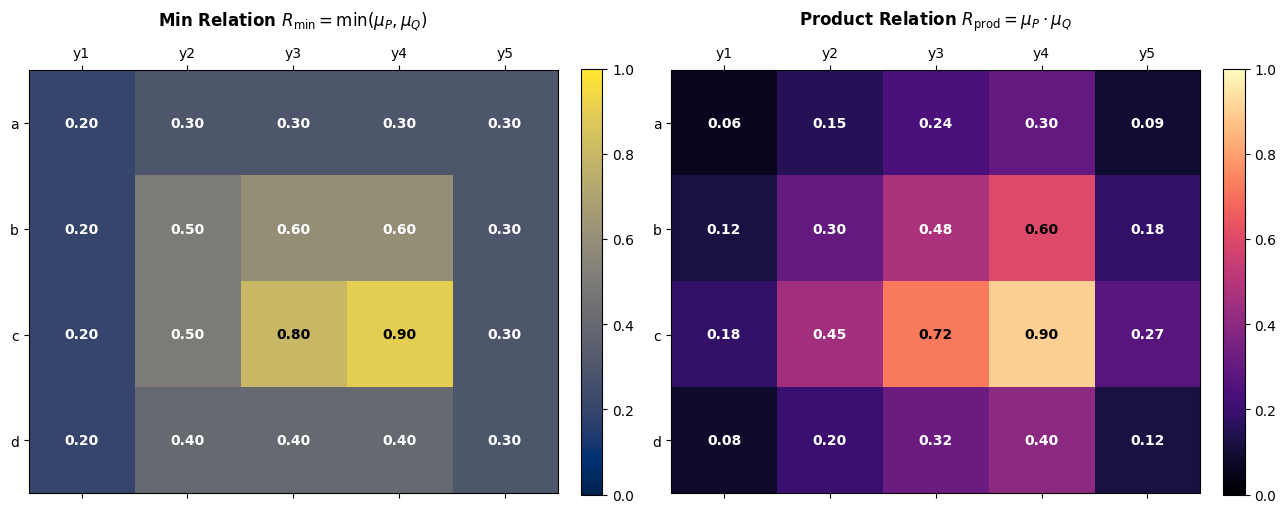

In [5]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Plot Min Relation
im1 = ax1.matshow(R_min, cmap='cividis', vmin=0, vmax=1)
fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)
ax1.set_title(r'Min Relation $R_{\min} = \min(\mu_P, \mu_Q)$', fontweight='bold', pad=15)
ax1.set_xticks(range(len(Y_names)))
ax1.set_yticks(range(len(X_names)))
ax1.set_xticklabels(Y_names)
ax1.set_yticklabels(X_names)

for i in range(len(X_names)):
    for j in range(len(Y_names)):
        ax1.text(j, i, f'{R_min[i, j]:.2f}', ha='center', va='center',
                 color='black' if R_min[i, j] > 0.6 else 'white', fontweight='bold')

# Plot Product Relation
im2 = ax2.matshow(R_prod, cmap='magma', vmin=0, vmax=1)
fig.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)
ax2.set_title(r'Product Relation $R_{\mathrm{prod}} = \mu_P \cdot \mu_Q$', fontweight='bold', pad=15)
ax2.set_xticks(range(len(Y_names)))
ax2.set_yticks(range(len(X_names)))
ax2.set_xticklabels(Y_names)
ax2.set_yticklabels(X_names)

for i in range(len(X_names)):
    for j in range(len(Y_names)):
        ax2.text(j, i, f'{R_prod[i, j]:.2f}', ha='center', va='center',
                 color='black' if R_prod[i, j] > 0.5 else 'white', fontweight='bold')

plt.tight_layout()
plt.show()


### 6. Results and Key Observations

| Feature Pair $(x_i, y_j)$ | $\mu_P(x_i)$ | $\mu_Q(y_j)$ | Min Relation $R_{\min}$ | Product Relation $R_{\text{prod}}$ |
| :---: | :---: | :---: | :---: | :---: |
| $(b, y_2)$ | $0.60$ | $0.50$ | **$0.50$** | **$0.30$** |
| $(c, y_3)$ | $0.90$ | $0.80$ | **$0.80$** | **$0.72$** |
| $(c, y_4)$ | $0.90$ | $1.00$ | **$0.90$** | **$0.90$** |
| $(d, y_5)$ | $0.40$ | $0.30$ | **$0.30$** | **$0.12$** |

#### Key Observations in Simple Words:
1. **Min vs. Product Operator:** The Product relation always produces relation strengths less than or equal to the Min relation ($R_{\text{prod}} \le R_{\min}$), acting as a stricter filter.
2. **Identity with Full Membership:** When one set has full membership ($\mu_Q(y_4) = 1.0$), both Min and Product operators yield identical results ($0.90$).
3. **Associative Chaining:** Fuzzy relations enable multi-stage automated reasoning across disparate technological or medical criteria.

---
### 7. Conclusion
1. We successfully constructed fuzzy relations using both Minimum and Algebraic Product Cartesian operators in Python.
2. We implemented and executed the Max-Min fuzzy relation composition algorithm.
3. We visually inspected and contrasted the relational matrices through annotated heatmaps.